# Explore > 'Social Score'

> How people feel they are supported by those around them

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis
from utils.plot_correlation_to_target import plot_correlation_to_target
from utils.preprocessing.transform import *

# Defaults

In [2]:
COLUMN = columns['SS']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

---

# Summary

In [4]:
train_df[COLUMN].info()

SocialSupport_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
SocialSupport_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

SocialSupport_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Social support
Non-Null Count  Dtype  
--------------  -----  
1549 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Social support,1549.0,0.812689,0.118762,0.29,0.753,0.835,0.905,0.987,42


In [5]:
missing_values_SocialSupport = train_df[COLUMN].isna().sum()
count_SocialSupport = train_df[COLUMN].count()

print(f"{missing_values_SocialSupport} missing values out of {count_SocialSupport} -> {round(missing_values_SocialSupport / count_SocialSupport, 2)}%")

10 missing values out of 1549 -> 0.01%


# Plots

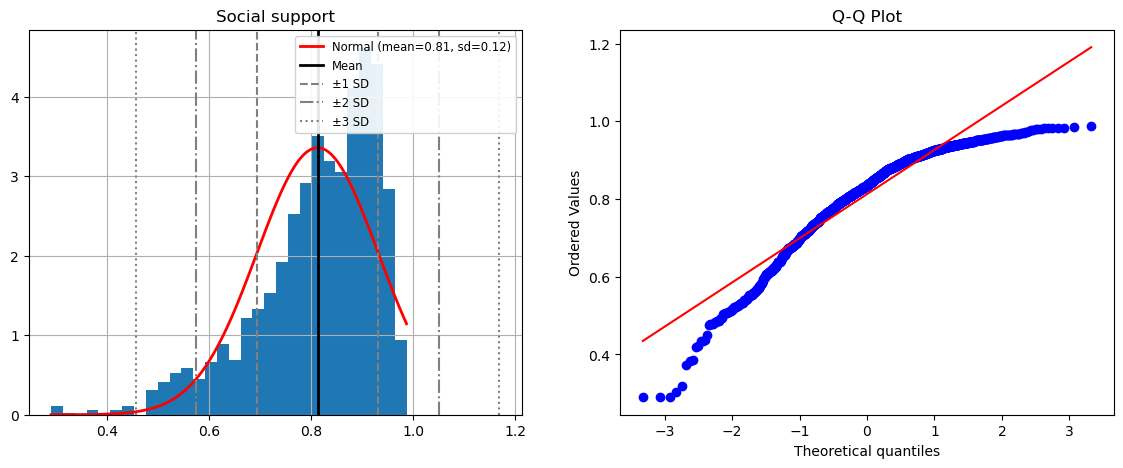

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN].dropna(),
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Correlation to Target

<Axes: title={'center': 'Life Ladder vs Social support'}, xlabel='Social support', ylabel='Life Ladder'>

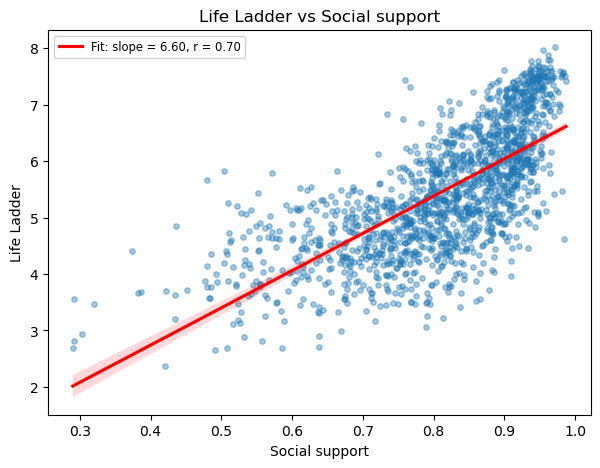

In [7]:
plot_correlation_to_target(
	df=train_df,
	feature="Social support",
	target=TARGET,
)

In [8]:
correlation_to_target_SocialSupport = train_df[TARGET].corr(train_df["Social support"])
print(f"Correlation: {correlation_to_target_SocialSupport:.3f}")

Correlation: 0.704


# Skew & Kurtosis

In [9]:
SocialSupportSkew = train_df[COLUMN].skew()
SocialSupportSkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df["Social support"])
SocialSupportKurtosis = train_df[COLUMN].kurt()
SocialSupportKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df['Log GDP per capita'])

print(f'Social Support Skew: {SocialSupportSkew:.3f} -> {SocialSupportSkew_RuleOfThumb}')
print(f'Social Support Kurtosis: {SocialSupportKurtosis:.3f} -> {SocialSupportKurtosis_RuleOfThumb}')

Social Support Skew: -1.138 -> Highly skewed
Social Support Kurtosis: 1.298 -> Mesokurtic (near-normal tails)


In [10]:
SocialSupportSkewTransformed = compare_all_transforms(series=train_df["Social support"])
SocialSupportSkewTransformed

,skew_before,skew_after,skew_diff,kurt_before,kurt_after,kurt_diff,skew_rule_after
transform,,,,,,,
quantile,-1.137804,0.000793,1.138597e+00,1.297841,0.634914,-6.629275e-01,Roughly symmetric
rank,-1.137804,-0.003232,1.134572e+00,1.297841,-1.201276,-2.499118e+00,Roughly symmetric
logit,-1.137804,-0.005150,1.132653e+00,1.297841,-0.126837,-1.424678e+00,Roughly symmetric
yeo_johnson,-1.137804,-0.174370,9.634339e-01,1.297841,-0.871743,-2.169585e+00,Roughly symmetric
box_cox,-1.137804,-0.218324,9.194802e-01,1.297841,-0.871204,-2.169046e+00,Roughly symmetric
cube,-1.137804,-0.396562,7.412415e-01,1.297841,-0.668452,-1.966294e+00,Roughly symmetric
arcsine_sqrt,-1.137804,-0.633462,5.043420e-01,1.297841,0.196686,-1.101156e+00,Moderately skewed
square,-1.137804,-0.706713,4.310905e-01,1.297841,-0.081475,-1.379316e+00,Moderately skewed
reflect_log,-1.137804,0.877412,2.015216e+00,1.297841,0.447138,-8.507031e-01,Moderately skewed


---

### Notes / Observations
#### General
- 10 missing values (0.6% of rows), the fewest of any feature.
- A 0 to 1 share ranging from 0.29 to 0.99 (mean 0.81, median 0.84).
- Strongly left skewed (skew -1.14): most countries are above 0.75 and bunch up against the ceiling of 1.0.
- The QQ plot drops off sharply at the low end: 42 IQR outliers, all very low support countries (below about 0.53).
- The kurtosis rule of thumb label in this notebook is computed on `Log GDP per capita` by mistake. The real kurtosis (1.30) is Leptokurtic (heavy tails), not Mesokurtic.
- Strong positive link to happiness (r = 0.70). The scatter bends slightly upward: happiness climbs faster once support passes about 0.8.
- Closely tied to GDP (r = 0.70) and Healthy life expectancy (r = 0.62).
- **Takeaway:** strong predictor, but the slight curve and the low outliers mean a straight line will not fit it perfectly.

#### Transforming
- Worth transforming: highly left skewed with heavy tails.
- yeo_johnson works best while keeping magnitudes: skew -1.14 to -0.17, kurtosis 1.30 to -0.87.
- cube is a simpler option (skew -0.40), and square is not enough (-0.71).
- log and sqrt make it worse (-1.84, -1.44): they stretch the low tail further, which is the wrong direction for left skew.
- rank gives a perfectly symmetric result but throws away how far apart countries are.
- **Pick:** yeo_johnson, fit on the train data only.

#### Scaling
- StandardScaler after the transform.
- Avoid MinMaxScaler on the raw values: the few very low outliers (0.29) set the minimum, so most countries get squeezed into the top of the range.

#### Imputing
- Only 10 rows, so a simple approach is enough.
- Use the median (0.835), not the mean (0.813): the left skew pulls the mean down.
- Its missing rows often line up with missing Positive and Negative affect (the same survey rows), so those two are poor helpers for model based imputation. GDP (r = 0.70) and Healthy life expectancy (r = 0.62) are better.